# Matrice densità, sfera di Bloch, prodotto tensore

### Subject: Quantum information I

`01_circuiti_passo_passo.ipynb` parte dai circuiti. Qui si torna un passo
indietro, sull'algebra che serve al modulo di Informazione Quantistica I:
stato puro vs misto, vettore di Bloch, traccia parziale.

Solo numpy. Qiskit non serve.

## 0. Setup

In [1]:
import sys
from pathlib import Path

_here = Path.cwd().resolve()
for candidate in (_here, _here.parent, _here.parent.parent):
    if (candidate / "_common").is_dir():
        sys.path.insert(0, str(candidate))
        break

import numpy as np
import matplotlib.pyplot as plt
from _common import PAULI_X, PAULI_Y, PAULI_Z, ket0, ket1, bloch_coordinates

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
I2 = np.eye(2, dtype=complex)
print("Setup ready.")

Setup ready.


## 1. Puro vs misto

Uno stato puro $|\psi\rangle$ ha $\rho=|\psi\rangle\langle\psi|$, $\rho^2=\rho$,
purezza $\mathrm{Tr}(\rho^2)=1$. Un misto è una combinazione convessa di puri.
Il qubit più misto è $\rho=I/2$, purezza $1/2$.

In [2]:
def ket_plus():
    return (ket0 + ket1) / np.sqrt(2)

def rho_pure(psi):
    psi = np.asarray(psi, dtype=complex).reshape(2, 1)
    return psi @ psi.conj().T

def purity(rho):
    return np.real(np.trace(rho @ rho))

rho_0 = rho_pure(ket0)
rho_plus = rho_pure(ket_plus())
rho_mix = 0.5 * rho_0 + 0.5 * rho_pure(ket1)
rho_I = 0.5 * I2

for name, rho in [("|0⟩⟨0|", rho_0), ("|+⟩⟨+|", rho_plus), ("50/50 |0⟩/|1⟩", rho_mix), ("I/2", rho_I)]:
    evals = np.real(np.linalg.eigvalsh(rho))
    print(f"{name:14s}  Tr={np.trace(rho).real:.3f}  Tr(ρ²)={purity(rho):.3f}  eigenvalues={evals}")

|0⟩⟨0|          Tr=1.000  Tr(ρ²)=1.000  eigenvalues=[0. 1.]
|+⟩⟨+|          Tr=1.000  Tr(ρ²)=1.000  eigenvalues=[0. 1.]
50/50 |0⟩/|1⟩   Tr=1.000  Tr(ρ²)=0.500  eigenvalues=[0.5 0.5]
I/2             Tr=1.000  Tr(ρ²)=0.500  eigenvalues=[0.5 0.5]


## 2. Sfera di Bloch

Ogni qubit (puro o misto) si scrive $\rho=(I+\vec r\cdot\vec\sigma)/2$ con
$|\vec r|\le 1$. Sulla sfera: puri. Dentro: misti. Il centro è $I/2$.

$$
r_i = \mathrm{Tr}(\rho\sigma_i).
$$

$|0\rangle$                               r=(+0.000, +0.000, +1.000)  |r|=1.000
$|1\rangle$                               r=(+0.000, +0.000, -1.000)  |r|=1.000
$|+\rangle$                               r=(+1.000, +0.000, +0.000)  |r|=1.000
$I/2$                                     r=(+0.000, +0.000, +0.000)  |r|=0.000
$0.7|0\rangle\langle0|+0.3|1\rangle\langle1|$  r=(+0.000, +0.000, +0.400)  |r|=0.400


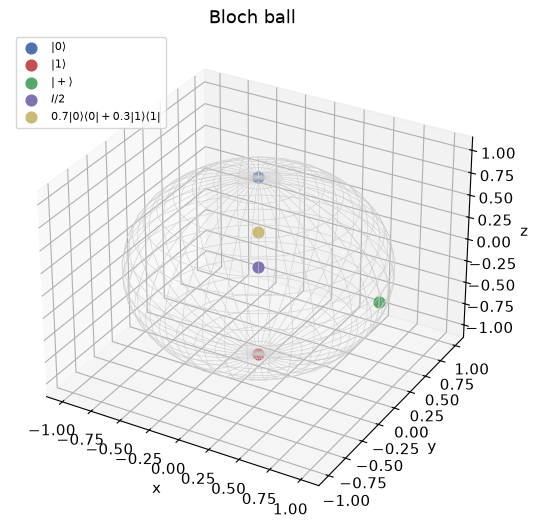

In [3]:
def bloch_from_rho(rho):
    return tuple(float(np.real(np.trace(rho @ s))) for s in (PAULI_X, PAULI_Y, PAULI_Z))

states = {
    r"$|0\rangle$": bloch_coordinates(ket0),
    r"$|1\rangle$": bloch_coordinates(ket1),
    r"$|+\rangle$": bloch_coordinates(ket_plus()),
    r"$I/2$": bloch_from_rho(rho_I),
    r"$0.7|0\rangle\langle0|+0.3|1\rangle\langle1|$": bloch_from_rho(0.7 * rho_0 + 0.3 * rho_pure(ket1)),
}
for name, r in states.items():
    print(f"{name:40s}  r=({r[0]:+.3f}, {r[1]:+.3f}, {r[2]:+.3f})  |r|={np.linalg.norm(r):.3f}")

fig = plt.figure(figsize=(5.4, 5.4))
ax = fig.add_subplot(111, projection="3d")
u, v = np.mgrid[0:2*np.pi:40j, 0:np.pi:20j]
ax.plot_wireframe(np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v), color="#cccccc", lw=0.4)
colors = ["#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974"]
for (name, r), col in zip(states.items(), colors):
    ax.scatter(*r, s=60, color=col, label=name)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
ax.set_title("Bloch ball")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 3. Prodotto tensore e traccia parziale

$|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt{2}$ è puro e entangled. Lo stato
ridotto di un qubit è però $I/2$: localmente è massimamente misto. Questo è il
segnale dell'entanglement (per uno stato puro bipartito: purezza ridotta $<1$).

In [4]:
phi_plus = (np.kron(ket0, ket0) + np.kron(ket1, ket1)) / np.sqrt(2)
rho_bell = phi_plus @ phi_plus.conj().T

def partial_trace_B(rho4):
    """Trace out qubit B (little-endian: B is the second factor)."""
    rho4 = rho4.reshape(2, 2, 2, 2)
    return np.trace(rho4, axis1=1, axis2=3)

rho_A = partial_trace_B(rho_bell)
print("Bell purity (global):", round(float(np.real(np.trace(rho_bell @ rho_bell))), 6))
print("Reduced ρ_A:\n", np.round(rho_A, 6))
print("Reduced purity:", round(purity(rho_A), 6))
print("Reduced Bloch:", bloch_from_rho(rho_A))
print("A local measurement on A sees no preferred direction — yet A and B are perfectly correlated.")

Bell purity (global): 1.0
Reduced ρ_A:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]
Reduced purity: 0.5
Reduced Bloch: (0.0, 0.0, 0.0)
A local measurement on A sees no preferred direction — yet A and B are perfectly correlated.


## Cosa ricordare

- $\rho$ è hermitiana, positiva, $\mathrm{Tr}\rho=1$. Puro $\Leftrightarrow$ $\mathrm{Tr}\rho^2=1$.
- Il qubit è un punto nella palla di Bloch; $I/2$ sta al centro.
- Tracciare un Bell puro dà $I/2$: l'informazione è nelle correlazioni, non in A o in B.

Questo è il ponte verso teleportation / CHSH in `01_circuiti_passo_passo.ipynb`.